# Sales & Profitability Analysis — SQL + Python

**Author:** Prathamesh Tirshu  
**Tools:** SQL (SQLite), Python (Pandas, NumPy, Matplotlib, Seaborn)  
**Dataset:** Superstore Sales (8,399 order lines, 2009–2012) — a public retail dataset of an office-supplies / furniture / technology retailer in Canada.

## Business problem
Management sees healthy sales but **profit margins are thin**. They want to know:
1. How are sales and profit trending?
2. Which **products, regions and customer segments** make or lose money?
3. Are **discounts** hurting profit?
4. How good is **shipping performance**?
5. Who are the **most valuable customers**, and which ones are we losing?

## Approach
1. Data cleaning and quality checks  
2. Load into a **SQL database** and answer business questions with SQL (CTEs, window functions, CASE WHEN)  
3. Trend, product, region, discount and shipping analysis in Python  
4. **Pareto (80/20)** and **RFM customer segmentation**  
5. Insights and recommendations

In [1]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
CHARTS = 'outputs/charts/'
money = plt.FuncFormatter(lambda v, _: f'{v/1e6:.1f}M' if abs(v) >= 1e6 else f'{v/1e3:.0f}K')

## 1. Load and clean

In [2]:
df = pd.read_csv('data/superstore_sales.csv')
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_').str.replace('-', '_')
df['order_date'] = pd.to_datetime(df['order_date'], format='%m/%d/%Y')
df['ship_date'] = pd.to_datetime(df['ship_date'], format='%m/%d/%Y')
print(df.shape)
df.head(3)

(8399, 21)


,row_id,order_id,order_date,order_priority,order_quantity,sales,discount,ship_mode,profit,unit_price,...,customer_name,province,region,customer_segment,product_category,product_sub_category,product_name,product_container,product_base_margin,ship_date
0,1,3,2010-10-13,Low,6,261.54,0.04,Regular Air,-213.25,38.94,...,Muhammed MacIntyre,Nunavut,Nunavut,Small Business,Office Supplies,Storage & Organization,"Eldon Base for stackable storage shelf, platinum",Large Box,0.80,2010-10-20
1,49,293,2012-10-01,High,49,10123.02,0.07,Delivery Truck,457.81,208.16,...,Barry French,Nunavut,Nunavut,Consumer,Office Supplies,Appliances,"1.7 Cubic Foot Compact ""Cube"" Office Refrigera...",Jumbo Drum,0.58,2012-10-02
2,50,293,2012-10-01,High,27,244.57,0.01,Regular Air,46.71,8.69,...,Barry French,Nunavut,Nunavut,Consumer,Office Supplies,Binders and Binder Accessories,"Cardinal Slant-D¨ Ring Binder, Heavy Gauge Vinyl",Small Box,0.39,2012-10-03


In [3]:
print('Missing values per column:')
print(df.isna().sum()[df.isna().sum() > 0])
print('\nDuplicate rows:', df.duplicated().sum())
print('Date range:', df['order_date'].min().date(), 'to', df['order_date'].max().date())
print('Ship date before order date:', (df['ship_date'] < df['order_date']).sum())
print('Negative sales:', (df['sales'] < 0).sum())

Missing values per column:
product_base_margin    63
dtype: int64

Duplicate rows: 0
Date range: 2009-01-01 to 2012-12-30
Ship date before order date: 0
Negative sales: 0


In [4]:
# Deeper consistency checks
multi_seg = df.groupby('customer_name')['customer_segment'].nunique()
multi_cust = df.groupby('order_id')['customer_name'].nunique()
print('Customers that appear in more than one segment:', (multi_seg > 1).sum())
print('Order IDs linked to more than one customer:', (multi_cust > 1).sum())

Customers that appear in more than one segment: 176
Order IDs linked to more than one customer: 21


**Data-quality notes**
- `product_base_margin` has a small number of missing values. We do not use it in the analysis, so we leave it as-is rather than invent values.
- No duplicates, no negative sales, and no orders shipped before they were placed.
- Some customer names appear in **more than one segment**, and a few order IDs map to more than one customer. In a real job I would raise this with the data owner. Here, segment-level counts therefore add up to more than the total number of unique customers — I note this when reporting.

In [5]:
# Helper columns
df['days_to_ship'] = (df['ship_date'] - df['order_date']).dt.days
df['year'] = df['order_date'].dt.year
df['month'] = df['order_date'].dt.to_period('M')
df['is_loss'] = df['profit'] < 0
df['discount_band'] = pd.cut(df['discount'], [-0.001, 0, 0.03, 0.06, 1], labels=['0%', '1-3%', '4-6%', '7%+'])

## 2. Business questions answered with SQL

The cleaned data is loaded into an in-memory **SQLite** database, and each question is answered with a SQL query. The same queries are saved in `sql/analysis_queries.sql`.

In [6]:
con = sqlite3.connect(':memory:')
sql_df = df.drop(columns=['month', 'discount_band', 'is_loss']).copy()
sql_df['order_date'] = sql_df['order_date'].dt.strftime('%Y-%m-%d')
sql_df['ship_date'] = sql_df['ship_date'].dt.strftime('%Y-%m-%d')
sql_df.to_sql('orders', con, index=False)

def q(sql):
    return pd.read_sql(sql, con)

# Q1. Overall KPIs
q('''
SELECT COUNT(DISTINCT order_id)                        AS total_orders,
       COUNT(DISTINCT customer_name)                   AS total_customers,
       ROUND(SUM(sales), 0)                            AS total_sales,
       ROUND(SUM(profit), 0)                           AS total_profit,
       ROUND(100.0 * SUM(profit) / SUM(sales), 2)      AS profit_margin_pct,
       ROUND(SUM(sales) / COUNT(DISTINCT order_id), 0) AS avg_order_value
FROM orders
''')

,total_orders,total_customers,total_sales,total_profit,profit_margin_pct,avg_order_value
0,5496,795,14915601.0,1521768.0,10.2,2714.0


In [7]:
# Q2. Year-over-year growth using the LAG window function
q('''
WITH yearly AS (
    SELECT strftime('%Y', order_date) AS year, SUM(sales) AS sales, SUM(profit) AS profit
    FROM orders GROUP BY year
)
SELECT year, ROUND(sales, 0) AS sales, ROUND(profit, 0) AS profit,
       ROUND(100.0 * profit / sales, 1) AS margin_pct,
       ROUND(100.0 * (sales - LAG(sales) OVER (ORDER BY year)) / LAG(sales) OVER (ORDER BY year), 1) AS sales_growth_pct
FROM yearly ORDER BY year
''')

,year,sales,profit,margin_pct,sales_growth_pct
0,2009,4209139.0,434539.0,10.3,NaN
1,2010,3549681.0,363871.0,10.3,-15.7
2,2011,3436817.0,381456.0,11.1,-3.2
3,2012,3719964.0,341902.0,9.2,8.2


In [8]:
# Q3. Loss-making sub-categories
q('''
SELECT product_category, product_sub_category,
       ROUND(SUM(sales), 0) AS sales, ROUND(SUM(profit), 0) AS profit,
       ROUND(100.0 * SUM(profit) / SUM(sales), 1) AS margin_pct
FROM orders
GROUP BY product_category, product_sub_category
ORDER BY profit ASC
LIMIT 6
''')

,product_category,product_sub_category,sales,profit,margin_pct
0,Furniture,Tables,1896008.0,-99063.0,-5.2
1,Furniture,Bookcases,822652.0,-33582.0,-4.1
2,Office Supplies,"Scissors, Rulers and Trimmers",80996.0,-7799.0,-9.6
3,Office Supplies,Rubber Bands,15007.0,-103.0,-0.7
4,Office Supplies,Storage & Organization,1070183.0,6664.0,0.6
5,Office Supplies,Pens & Art Supplies,167107.0,7565.0,4.5


In [9]:
# Q4. Regions ranked by profit (RANK window function)
q('''
SELECT region, ROUND(SUM(sales), 0) AS sales, ROUND(SUM(profit), 0) AS profit,
       ROUND(100.0 * SUM(profit) / SUM(sales), 1) AS margin_pct,
       RANK() OVER (ORDER BY SUM(profit) DESC) AS profit_rank
FROM orders GROUP BY region ORDER BY profit_rank
''')

,region,sales,profit,margin_pct,profit_rank
0,Ontario,3063212.0,346869.0,11.3,1
1,Prarie,2837305.0,321160.0,11.3,2
2,West,3597549.0,297009.0,8.3,3
3,Atlantic,2014248.0,238961.0,11.9,4
4,Quebec,1510195.0,140427.0,9.3,5
5,Northwest Territories,800847.0,100653.0,12.6,6
6,Yukon,975867.0,73849.0,7.6,7
7,Nunavut,116376.0,2841.0,2.4,8


In [10]:
# Q5. Discount impact (CASE WHEN)
q('''
SELECT CASE WHEN discount = 0 THEN '0%' WHEN discount <= 0.03 THEN '1-3%'
            WHEN discount <= 0.06 THEN '4-6%' ELSE '7%+' END AS discount_band,
       COUNT(*) AS order_lines,
       ROUND(AVG(profit), 1) AS avg_profit_per_line,
       ROUND(100.0 * SUM(profit) / SUM(sales), 1) AS margin_pct,
       ROUND(100.0 * AVG(CASE WHEN profit < 0 THEN 1.0 ELSE 0 END), 1) AS pct_loss_making_lines
FROM orders GROUP BY discount_band ORDER BY MIN(discount)
''')

,discount_band,order_lines,avg_profit_per_line,margin_pct,pct_loss_making_lines
0,0%,756,248.9,12.6,46.3
1,1-3%,2350,243.0,13.6,47.1
2,4-6%,2290,149.3,8.4,50.7
3,7%+,3003,140.0,8.1,54.8


In [11]:
# Q6. Best-selling sub-category in each region (CTE + ROW_NUMBER)
q('''
WITH ranked AS (
    SELECT region, product_sub_category, SUM(sales) AS sales,
           ROW_NUMBER() OVER (PARTITION BY region ORDER BY SUM(sales) DESC) AS rn
    FROM orders GROUP BY region, product_sub_category
)
SELECT region, product_sub_category, ROUND(sales, 0) AS sales FROM ranked WHERE rn = 1 ORDER BY sales DESC
''')

,region,product_sub_category,sales
0,West,Office Machines,602158.0
1,Prarie,Office Machines,474034.0
2,Ontario,Chairs & Chairmats,438172.0
3,Atlantic,Office Machines,306323.0
4,Quebec,Tables,275689.0
5,Yukon,Office Machines,182127.0
6,Northwest Territories,Office Machines,139087.0
7,Nunavut,Chairs & Chairmats,31028.0


## 3. Sales trend

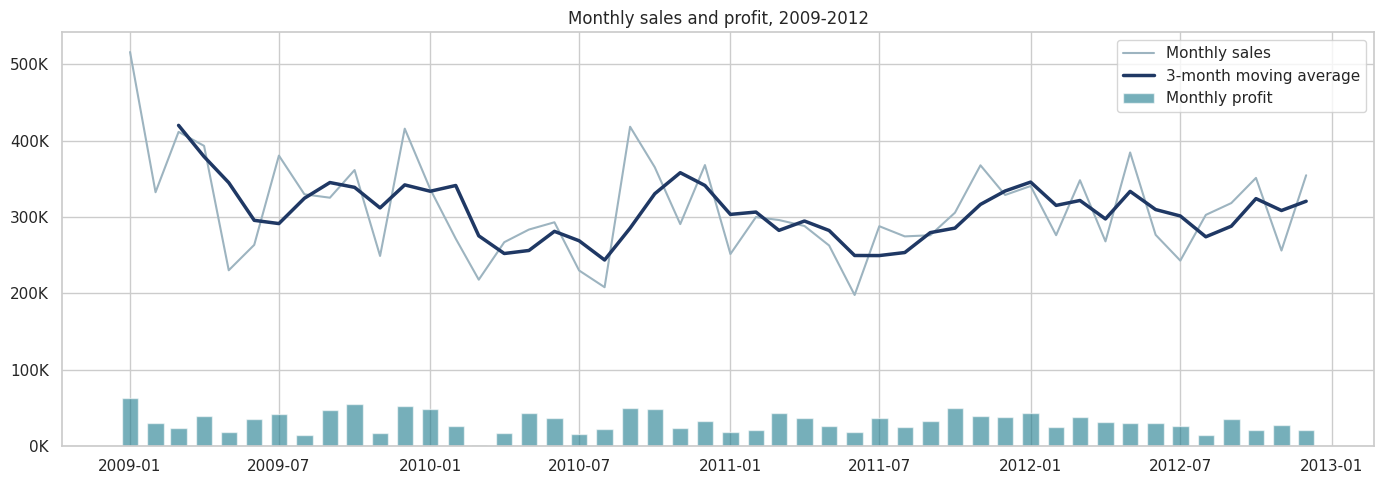

Best month : Jan 2009 (516,303)
Worst month: Jun 2011 (197,741)
Months with a loss: 0


In [12]:
monthly = df.groupby('month')[['sales', 'profit']].sum()
monthly.index = monthly.index.to_timestamp()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(monthly.index, monthly['sales'], color='#9DB4C0', label='Monthly sales')
ax.plot(monthly.index, monthly['sales'].rolling(3).mean(), color='#1F3864', lw=2.5, label='3-month moving average')
ax.bar(monthly.index, monthly['profit'], width=20, color='#1B7A8C', alpha=0.6, label='Monthly profit')
ax.yaxis.set_major_formatter(money); ax.set_title('Monthly sales and profit, 2009-2012'); ax.legend()
plt.tight_layout(); plt.savefig(CHARTS + '01_monthly_trend.png', dpi=120); plt.show()

print('Best month :', monthly['sales'].idxmax().strftime('%b %Y'), f"({monthly['sales'].max():,.0f})")
print('Worst month:', monthly['sales'].idxmin().strftime('%b %Y'), f"({monthly['sales'].min():,.0f})")
print('Months with a loss:', (monthly['profit'] < 0).sum())

## 4. Product profitability

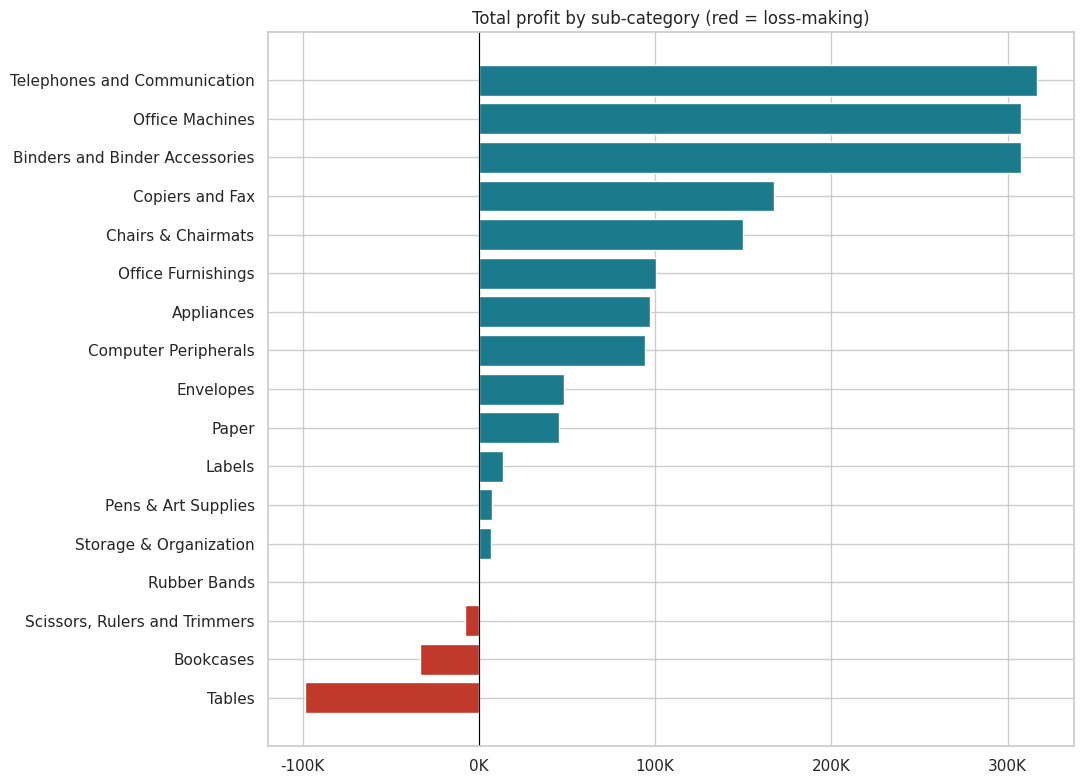

,sales,profit,margin_pct
product_category,,,
Furniture,5178591.0,117433.0,2.0
Office Supplies,3752762.0,518021.0,14.0
Technology,5984248.0,886314.0,15.0


In [13]:
sub = df.groupby(['product_category', 'product_sub_category'])[['sales', 'profit']].sum().reset_index()
sub['margin_pct'] = 100 * sub['profit'] / sub['sales']
sub = sub.sort_values('profit')

plt.figure(figsize=(11, 8))
colors = ['#C0392B' if p < 0 else '#1B7A8C' for p in sub['profit']]
plt.barh(sub['product_sub_category'], sub['profit'], color=colors)
plt.gca().xaxis.set_major_formatter(money); plt.axvline(0, color='black', lw=0.8)
plt.title('Total profit by sub-category (red = loss-making)'); plt.tight_layout()
plt.savefig(CHARTS + '02_profit_by_subcategory.png', dpi=120); plt.show()

cat = df.groupby('product_category')[['sales', 'profit']].sum()
cat['margin_pct'] = (100 * cat['profit'] / cat['sales']).round(1)
cat.round(0)

## 5. Region and segment performance

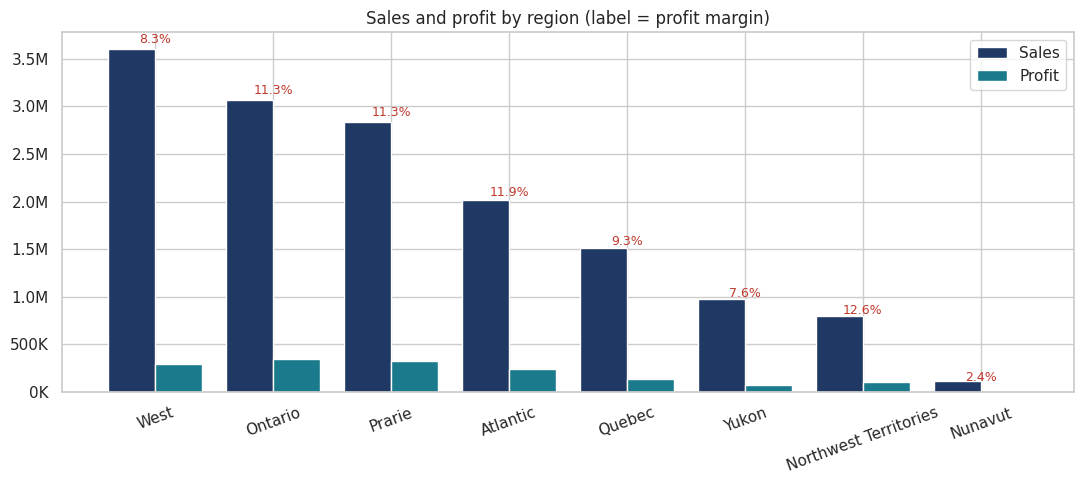

,sales,profit,margin_pct
region,,,
West,3597549.3,297008.6,8.3
Ontario,3063212.5,346868.5,11.3
Prarie,2837304.6,321160.1,11.3
Atlantic,2014248.2,238960.7,11.9
Quebec,1510195.1,140426.6,9.3
Yukon,975867.4,73849.2,7.6
Northwest Territories,800847.3,100653.1,12.6
Nunavut,116376.5,2841.1,2.4


In [14]:
reg = df.groupby('region')[['sales', 'profit']].sum().sort_values('sales', ascending=False)
reg['margin_pct'] = 100 * reg['profit'] / reg['sales']

fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(reg))
ax.bar(x - 0.2, reg['sales'], 0.4, label='Sales', color='#1F3864')
ax.bar(x + 0.2, reg['profit'], 0.4, label='Profit', color='#1B7A8C')
for i, m in enumerate(reg['margin_pct']):
    ax.text(i, reg['sales'].iloc[i] * 1.02, f'{m:.1f}%', ha='center', fontsize=9, color='#C0392B')
ax.set_xticks(x); ax.set_xticklabels(reg.index, rotation=20); ax.yaxis.set_major_formatter(money)
ax.set_title('Sales and profit by region (label = profit margin)'); ax.legend()
plt.tight_layout(); plt.savefig(CHARTS + '03_region_performance.png', dpi=120); plt.show()
reg.round(1)

## 6. Do discounts hurt profit?

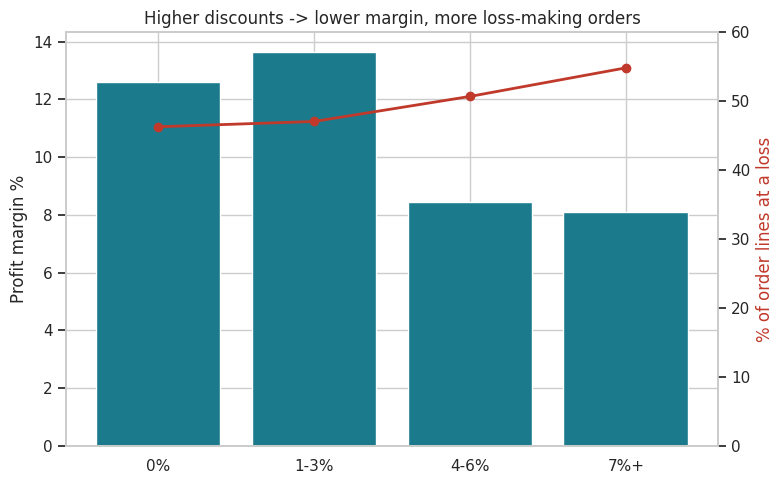

,lines,sales,profit,loss_share,margin_pct
discount_band,,,,,
0%,756,1493748.22,188188.77,0.46,12.60
1-3%,2350,4185574.82,571055.20,0.47,13.64
4-6%,2290,4050804.89,341965.83,0.51,8.44
7%+,3003,5185472.90,420558.18,0.55,8.11


In [15]:
disc = df.groupby('discount_band', observed=True).agg(lines=('sales', 'size'), sales=('sales', 'sum'),
                                                      profit=('profit', 'sum'), loss_share=('is_loss', 'mean'))
disc['margin_pct'] = 100 * disc['profit'] / disc['sales']

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(disc.index.astype(str), disc['margin_pct'], color='#1B7A8C')
ax2 = ax.twinx(); ax2.plot(disc.index.astype(str), disc['loss_share'] * 100, color='#C0392B', marker='o', lw=2)
ax.set_ylabel('Profit margin %'); ax2.set_ylabel('% of order lines at a loss', color='#C0392B'); ax2.set_ylim(0, 60)
ax.set_title('Higher discounts -> lower margin, more loss-making orders'); ax2.grid(False)
plt.tight_layout(); plt.savefig(CHARTS + '04_discount_impact.png', dpi=120); plt.show()
disc.round(2)

## 7. Shipping performance

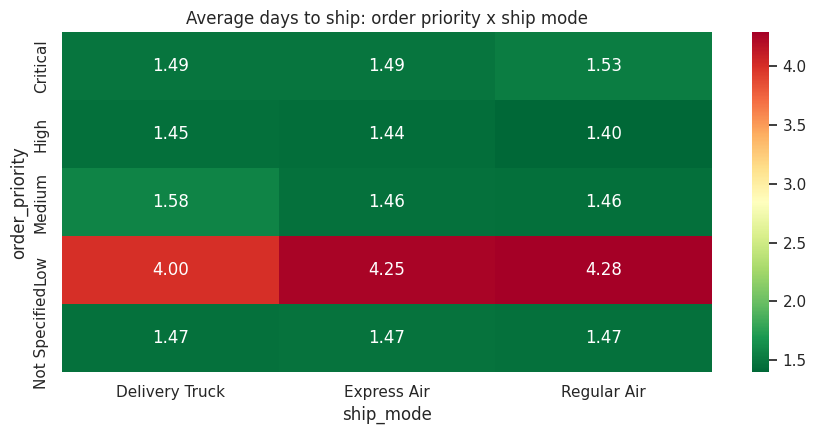

                mean  max
order_priority           
Critical        1.52   84
High            1.41    3
Low             4.24   92
Medium          1.47   19
Not Specified   1.47   28

Share of revenue spent on shipping: 0.7%


In [16]:
ship = df.pivot_table(index='order_priority', columns='ship_mode', values='days_to_ship', aggfunc='mean')
ship = ship.reindex(['Critical', 'High', 'Medium', 'Low', 'Not Specified'])

plt.figure(figsize=(9, 4.5))
sns.heatmap(ship, annot=True, fmt='.2f', cmap='RdYlGn_r')
plt.title('Average days to ship: order priority x ship mode'); plt.tight_layout()
plt.savefig(CHARTS + '05_shipping_heatmap.png', dpi=120); plt.show()

print(df.groupby('order_priority')['days_to_ship'].agg(['mean', 'max']).round(2))
print('\nShare of revenue spent on shipping: {:.1%}'.format(df['shipping_cost'].sum() / df['sales'].sum()))

## 8. Customer analysis — Pareto (80/20) and RFM segmentation

Top 20% of customers (159) generate 46% of sales


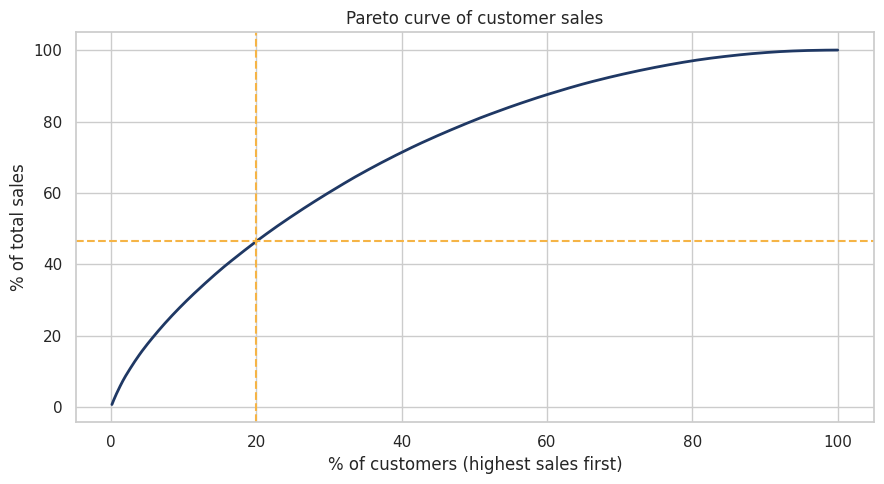

In [17]:
cust_sales = df.groupby('customer_name')['sales'].sum().sort_values(ascending=False)
cum_share = cust_sales.cumsum() / cust_sales.sum()
top20 = int(len(cust_sales) * 0.2)
print(f'Top 20% of customers ({top20}) generate {cum_share.iloc[top20 - 1]:.0%} of sales')

plt.figure(figsize=(9, 5))
plt.plot(np.arange(1, len(cum_share) + 1) / len(cum_share) * 100, cum_share.values * 100, color='#1F3864', lw=2)
plt.axvline(20, ls='--', color='#F5B446'); plt.axhline(cum_share.iloc[top20 - 1] * 100, ls='--', color='#F5B446')
plt.xlabel('% of customers (highest sales first)'); plt.ylabel('% of total sales'); plt.title('Pareto curve of customer sales')
plt.tight_layout(); plt.savefig(CHARTS + '06_pareto_customers.png', dpi=120); plt.show()

**RFM** scores every customer on three behaviours:
- **Recency** — days since their last order (lower is better)
- **Frequency** — number of distinct orders
- **Monetary** — total sales

Each is scored 1–4 using quartiles, then combined into business segments.

In [18]:
snapshot = df['order_date'].max() + pd.Timedelta(days=1)
rfm = df.groupby('customer_name').agg(recency=('order_date', lambda d: (snapshot - d.max()).days),
                                      frequency=('order_id', 'nunique'), monetary=('sales', 'sum'))
rfm['R'] = pd.qcut(rfm['recency'], 4, labels=[4, 3, 2, 1]).astype(int)          # recent = high score
rfm['F'] = pd.qcut(rfm['frequency'].rank(method='first'), 4, labels=[1, 2, 3, 4]).astype(int)
rfm['M'] = pd.qcut(rfm['monetary'], 4, labels=[1, 2, 3, 4]).astype(int)

def segment(r):
    if r.R >= 3 and r.F >= 3 and r.M >= 3: return 'Champions'
    if r.F >= 3 and r.M >= 3:              return 'Loyal - at risk' if r.R <= 2 else 'Loyal'
    if r.R >= 3 and r.F <= 2:              return 'Recent / promising'
    if r.R <= 2 and r.F <= 2 and r.M <= 2: return 'Lost / low value'
    return 'Needs attention'

rfm['segment'] = rfm.apply(segment, axis=1)
seg = rfm.groupby('segment').agg(customers=('recency', 'size'), avg_recency_days=('recency', 'mean'),
                                 avg_orders=('frequency', 'mean'), total_sales=('monetary', 'sum'))
seg['share_of_sales_%'] = 100 * seg['total_sales'] / seg['total_sales'].sum()
seg = seg.sort_values('total_sales', ascending=False).round(1)
rfm.to_csv('outputs/rfm_customer_segments.csv')
seg

,customers,avg_recency_days,avg_orders,total_sales,share_of_sales_%
segment,,,,,
Champions,188,67.1,11.1,6404917.7,42.9
Loyal - at risk,101,276.9,9.4,3008430.1,20.2
Needs attention,175,274.7,6.5,2647533.9,17.8
Recent / promising,145,81.6,4.6,1762282.1,11.8
Lost / low value,186,459.3,3.7,1092437.0,7.3


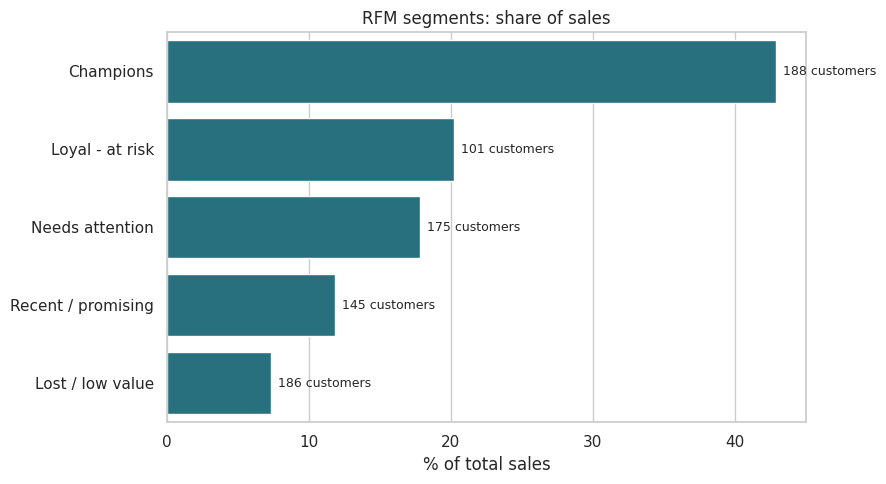

In [19]:
plt.figure(figsize=(9, 5))
sns.barplot(x=seg['share_of_sales_%'], y=seg.index, color='#1B7A8C')
for i, (c, s) in enumerate(zip(seg['customers'], seg['share_of_sales_%'])):
    plt.text(s + 0.5, i, f'{int(c)} customers', va='center', fontsize=9)
plt.xlabel('% of total sales'); plt.ylabel(''); plt.title('RFM segments: share of sales')
plt.tight_layout(); plt.savefig(CHARTS + '07_rfm_segments.png', dpi=120); plt.show()

In [20]:
# Save summary tables for reporting / Power BI
sub.to_csv('outputs/subcategory_profitability.csv', index=False)
reg.to_csv('outputs/region_performance.csv')
monthly.to_csv('outputs/monthly_sales_profit.csv')
print('Summary tables saved to outputs/')

Summary tables saved to outputs/


## 9. Key insights & recommendations

**Insights**
1. **Thin margins:** ~14.9M in sales but only ~1.5M profit (about 10% margin). Sales fell in 2010–2011 and recovered in 2012, while profit in 2012 was the lowest of the four years.
2. **Tables and Bookcases lose money** — Furniture's two biggest loss-makers. Telephones & Communication, Office Machines and Binders (30% margin) are the profit engines; Furniture as a whole earns only a 2% margin.
3. **Discounts erode profit:** margin drops from roughly 13% at 0–3% discount to about 8% at 4%+ discount, and the share of loss-making order lines rises.
4. **Regional gap:** Ontario and the Prairies earn the most profit; the West has the **highest sales but a lower margin**; Nunavut barely breaks even.
5. **Shipping:** "Low"-priority orders take around 4 days versus about 1.5 days for other priorities; Delivery Truck is far more expensive per order than air shipping (bulky furniture).
6. **Customer concentration:** the top 20% of customers generate nearly half (about 46%) of sales, and a meaningful share of sales sits with "Loyal - at risk" customers who have not ordered recently.

**Recommendations**
1. Review **pricing and discount rules for Tables and Bookcases** — cap discounts or stop selling the worst products at a loss.
2. Introduce a **discount approval rule** above 5%.
3. Investigate why the **West** has lower margins (discounting, shipping cost, product mix).
4. Launch a **win-back campaign** for "Loyal - at risk" customers and a VIP programme for Champions.
5. Build a monthly **Power BI dashboard** from the `outputs/` tables to track margin by sub-category, region and discount band.